# Consumption and income — ARDL with makystats

**Series.** US quarterly log real consumption and log real disposable income (`data/us_macro_quarterly.csv`).

**Deterministic case.** PSS **case 2** (restricted constant): on this sample, case 3 often fails to reject “no levels relation”, while case 2 does.

**Order selection (case 2).**

| Criterion | Preferred |
|-----------|-----------|
| **BIC and AIC** | `ARDL(1; 2)` — one lag of \(C\), two lags of income |

Main model: **ARDL(1, 2), case 2**. A symmetric ARDL(2, 2) is close but **not** first on IC.


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from makystats import ardl, select_ardl_order

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

## 2. Data


In [2]:
md = pd.read_csv("data/us_macro_quarterly.csv")
md.index = pd.PeriodIndex.from_fields(
    year=md["year"].astype(int), quarter=md["quarter"].astype(int), freq="Q"
)
c = np.log(md["realcons"].astype(float))
c.name = "log_c"
inc = np.log(md["realdpi"].astype(float))
x = inc.to_frame("income")
print(c.index[0], "→", c.index[-1], f"({len(c)} obs.)")

1959Q1 → 2009Q3 (203 obs.)


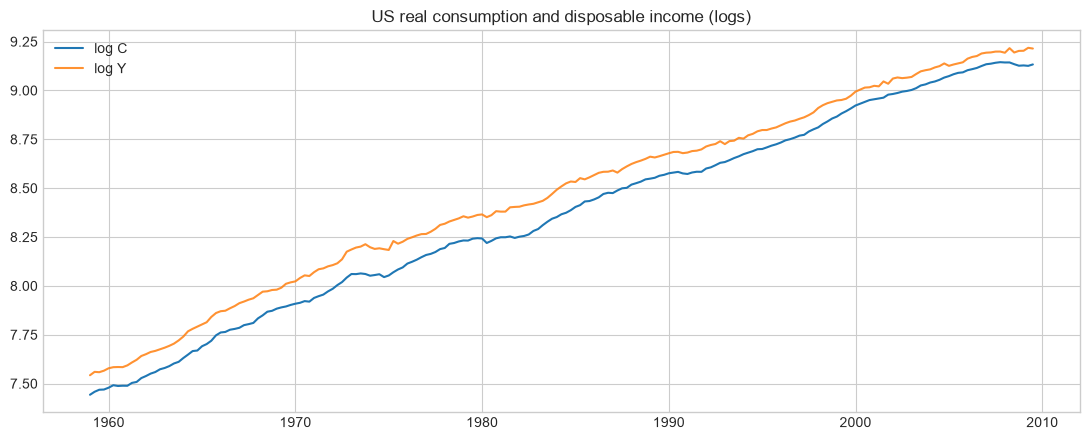

In [3]:
fig, ax = plt.subplots()
ax.plot(c.to_timestamp(), label="log C")
ax.plot(inc.to_timestamp(), label="log Y", alpha=0.85)
ax.legend()
ax.set_title("US real consumption and disposable income (logs)")
fig.tight_layout()
plt.show()

## 3. Order selection (case 2)


In [4]:
table = select_ardl_order(
    c, x=x, maxlag=4, maxorder=4, case=2, ic="bic", verbose=False
)
print(table.head(8))
print("Best (BIC):", table.index[0])

            p          order          aic          bic         hqic  \
ARDL(1; 2)  1  {'income': 2} -1492.085429 -1475.568904 -1485.402127   
ARDL(2; 2)  2  {'income': 2} -1490.903539 -1471.083709 -1482.883576   
ARDL(3; 2)  3  {'income': 2} -1491.118331 -1468.030110 -1481.774881   
ARDL(1; 1)  1  {'income': 1} -1478.336195 -1465.103125 -1472.982071   
ARDL(1; 3)  1  {'income': 3} -1483.462997 -1463.673093 -1475.454326   
ARDL(3; 3)  3  {'income': 3} -1489.424512 -1463.037973 -1478.746283   
ARDL(2; 1)  2  {'income': 1} -1477.492378 -1460.975853 -1470.809076   
ARDL(3; 1)  3  {'income': 1} -1480.566968 -1460.777063 -1472.558296   

                    ll  n_obs  case  q_income  q  
ARDL(1; 2)  751.042714    201     2         2  2  
ARDL(2; 2)  751.451769    201     2         2  2  
ARDL(3; 2)  752.559166    200     2         2  2  
ARDL(1; 1)  743.168098    202     2         1  1  
ARDL(1; 3)  747.731499    200     2         3  3  
ARDL(3; 3)  752.712256    200     2         3  3  
ARD

### Reading the table

- **ARDL(1; 2)** leads both BIC and AIC.
- ARDL(2; 2) is second-tier on BIC — acceptable robustness check, not the primary report.


## 4. Main model: ARDL(1, 2), case 2


In [5]:
res = ardl(c, x=x, lags=1, order=2, case=2).fit(verbose=False)
print(res.summary())

                              ARDL Model Results                              
Dep. Variable: log_c                                     No. Observations: 201
Model:         ARDL(1, 2)                            Log Likelihood:   751.043
Method:        OLS (conditional)                  S.D. of innov.:   0.00578217
Case (PSS):    2 (Rest. Constant)                  AIC:              -1492.085
Date:          Tue, 27 Oct 2026                    BIC:              -1475.569
Time:          17:01:56                            HQIC:             -1485.402
                coef    std err          t      P>|t|     [0.025     0.975]
const        -0.0041     0.0112    -0.3708     0.7112    -0.0262     0.0179
log_c.L1      0.9636     0.0209    46.0444     0.0000     0.9223     1.0049
income.L0     0.3617     0.0478     7.5742     0.0000     0.2675     0.4558
income.L1    -0.0909     0.0638    -1.4245     0.1559    -0.2167     0.0349
income.L2    -0.2340     0.0473    -4.9479     0.0000    -0.3272   

### Interpretation

- Long-run coefficient on income near **1** (proportional consumption–income relation in logs).
- Case 2 restricts the constant into the cointegrating space — **state the case** when you publish the F-test.


## 5. UECM (Conditional EC) and bounds test

`summary_uecm()` reports the **conditional error-correction** form (levels of \(y\) and \(x\) lagged, short-run differences) and the **long-run multipliers** \(\theta\).

`summary_bounds()` is the Pesaran / Narayan **F-bounds** test for a levels relationship.


In [6]:
print(res.summary_uecm())
print(res.summary_bounds())

                              UECM Model Results                              
Dep. Variable: D.log_c                                   No. Observations: 201
Model:         UECM(1, …)                            Log Likelihood:   751.043
Method:        OLS (reparam. ARDL)                 AIC:              -1492.085
Case (PSS):    2 (Rest. Constant)                  BIC:              -1475.569
                  coef    std err          t      P>|t|     [0.025     0.975]
const          -0.0041     0.0112    -0.3708     0.7112    -0.0262     0.0179
log_c.L1       -0.0364     0.0209    -1.7384     0.0837    -0.0777     0.0049
income.L1       0.0368     0.0216     1.7014     0.0905    -0.0059     0.0795
D.income.L0     0.3617     0.0478     7.5742     0.0000     0.2675     0.4558
D.income.L1     0.2340     0.0473     4.9479     0.0000     0.1407     0.3272

Long run (multiplicateurs)
----------------------------------------
             coef    std err          t      P>|t|
const     -0.1138

## 6. ECM and diagnostics


                            ECM (Error Correction)                            
                  coef    std err          t      P>|t|
COINTEQ        -0.0364     0.0070    -5.1932     0.0000
D.income.L0     0.3617     0.0442     8.1826     0.0000
D.income.L1     0.2340     0.0467     5.0063     0.0000

Half-life (approx.): 18.704
α=-0.0364 (p=5.114e-07) : retour vers l'équilibre (α<0)
None


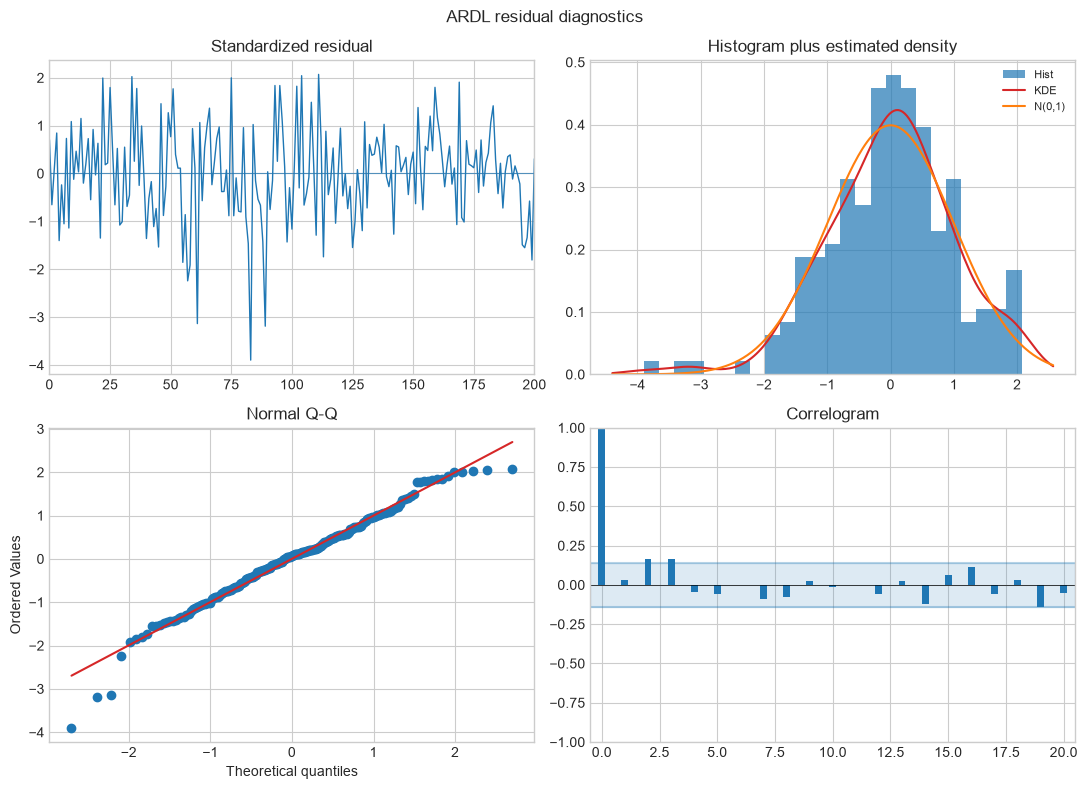

In [7]:
print(res.summary_ecm())
fig = res.plot_diagnostics()
plt.show()

## 7. Robustness: case 3 (often weaker bounds)


In [8]:
res3 = ardl(c, x=x, lags=1, order=2, case=3).fit(verbose=False)
print(res3.summary_bounds())


                       Bounds test (Pesaran / Narayan)                        
case=3 (Constant)    k=1    n=201    F=1.887766
t-stat (y.L1) = -1.738383
restrictions (q) = 2

Pesaran, Shin & Smith (2001) — asymptotic
          I(0)       I(1)     F-stat              Décision
1%      5.1720     6.3220     1.8878  Pas de cointégration
5%      3.8020     4.8120     1.8878  Pas de cointégration
10%     3.1740     4.1080     1.8878  Pas de cointégration

Narayan (2005) — finite sample
          I(0)       I(1)     F-stat              Décision
1%      7.0950     8.2600     1.8878  Pas de cointégration
5%      5.0600     5.9300     1.8878  Pas de cointégration
10%     4.1350     4.8950     1.8878  Pas de cointégration

Synthèse (5%) : pas de cointégration (ne rejette pas H0)
None


## Takeaways

1. **Case 2 + ARDL(1, 2)** is the IC-aligned specification on this file.
2. Do not report case 3 as “the” result if the bounds only work under case 2 — discuss both.
3. Elasticity ≈ 1 is the economic benchmark alongside the F-test.
